# Lecture Notes: Derivatives of Trigonometric Functions
*Stewart, **Calculus**, 9th ed., §3.3*

**Learning objectives.** By the end of this lecture you should be able to:
1. Explain the two key limits $\displaystyle\lim_{\theta\to0}\frac{\sin\theta}{\theta} = 1$ and $\displaystyle\lim_{\theta\to0}\frac{\cos\theta - 1}{\theta} = 0$, and why they need **radians**.
2. Derive $\dfrac{d}{dx}(\sin x) = \cos x$ and $\dfrac{d}{dx}(\cos x) = -\sin x$ from the limit definition.
3. Use the Quotient Rule to find the derivatives of $\tan x$, $\cot x$, $\sec x$, and $\csc x$.
4. Apply these formulas to products, quotients, higher derivatives, and simple harmonic motion.
5. Evaluate trigonometric limits by reducing them to $\dfrac{\sin\theta}{\theta}$.
6. Check every answer symbolically with **SymPy** and numerically with **NumPy**.

In [20]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Math, display

sp.init_printing()
x, t, h, theta = sp.symbols("x t h theta")

## 1. Where we are

From [§3.1](derivatives_of_polynomials_and_exp_functions.ipynb) and [§3.2](product_and_quotient_rules.ipynb) we can differentiate:

| Function | Derivative |
|---|---|
| $c$ | $0$ |
| $x^n$ | $n x^{n-1}$ |
| $e^x$ | $e^x$ |
| $c\,f \pm g$ | $c\,f' \pm g'$ |
| $f\,g$ | $f g' + g f'$ |
| $\dfrac{f}{g}$ | $\dfrac{g f' - f g'}{g^2}$ |

In this section we add the six trigonometric functions. **Throughout, angles are measured in radians.**

As before, the helper below compares a derivative found by hand with SymPy's answer.

## 2. A graphical guess

Before proving anything, let's estimate the slope of $y = \sin x$ at many points and plot it. The slope is $1$ at $x = 0$, $0$ at the peaks and troughs, and $-1$ at $x = \pi$. That pattern looks like $\cos x$.

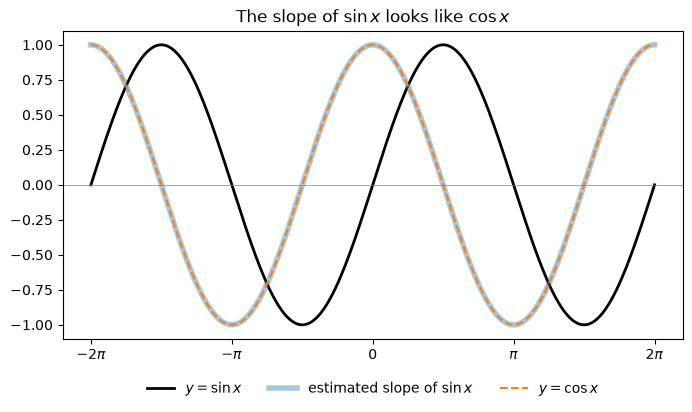

In [21]:
xs = np.linspace(-2 * np.pi, 2 * np.pi, 400)
slopes = np.gradient(np.sin(xs), xs)  # numerical estimate of the slope

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(xs, np.sin(xs), "k", lw=2, label=r"$y = \sin x$")
ax.plot(xs, slopes, lw=4, alpha=0.4, label=r"estimated slope of $\sin x$")
ax.plot(xs, np.cos(xs), "--", lw=1.5, label=r"$y = \cos x$")
ax.axhline(0, color="gray", lw=0.5)
ax.set_xticks(np.arange(-2, 3) * np.pi, [r"$-2\pi$", r"$-\pi$", "0", r"$\pi$", r"$2\pi$"])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
ax.set_title(r"The slope of $\sin x$ looks like $\cos x$")
plt.show()

## 3. Two important limits

To prove the guess, we need two limits.

**Limit 1.** $$\boxed{\lim_{\theta\to0}\frac{\sin\theta}{\theta} = 1}$$

**Proof (squeeze).** Take $0 < \theta < \pi/2$ and a unit circle. Comparing the areas of the small triangle, the circular sector, and the large triangle that share the angle $\theta$ gives
$$\tfrac12\sin\theta \;<\; \tfrac12\theta \;<\; \tfrac12\tan\theta.$$
Divide by $\tfrac12\sin\theta > 0$ and take reciprocals:
$$\cos\theta \;<\; \frac{\sin\theta}{\theta} \;<\; 1.$$
As $\theta\to0^+$, $\cos\theta\to1$, so by the Squeeze Theorem $\dfrac{\sin\theta}{\theta}\to1$. The function $\dfrac{\sin\theta}{\theta}$ is even, so the left-hand limit is also $1$. $\blacksquare$

**Limit 2.** $$\boxed{\lim_{\theta\to0}\frac{\cos\theta - 1}{\theta} = 0}$$

**Proof.** Multiply the numerator and denominator by $\cos\theta + 1$ and use $\cos^2\theta - 1 = -\sin^2\theta$:
$$\frac{\cos\theta - 1}{\theta} = \frac{-\sin^2\theta}{\theta(\cos\theta+1)} = -\frac{\sin\theta}{\theta}\cdot\frac{\sin\theta}{\cos\theta + 1}
\;\xrightarrow{\theta\to0}\; -1\cdot\frac{0}{2} = 0. \qquad\blacksquare$$

A table of values supports both limits:

In [22]:
print(f"{'theta':>10} {'sin(θ)/θ':>14} {'(cos(θ)-1)/θ':>16}")
for th in [1, 0.5, 0.1, 0.01, 0.001]:
    print(f"{th:>10} {np.sin(th) / th:>14.10f} {(np.cos(th) - 1) / th:>16.10f}")

print()
print("SymPy: lim sin(θ)/θ     =", sp.limit(sp.sin(theta) / theta, theta, 0))
print("SymPy: lim (cos(θ)-1)/θ =", sp.limit((sp.cos(theta) - 1) / theta, theta, 0))

     theta       sin(θ)/θ     (cos(θ)-1)/θ
         1   0.8414709848    -0.4596976941
       0.5   0.9588510772    -0.2448348762
       0.1   0.9983341665    -0.0499583472
      0.01   0.9999833334    -0.0049999583
     0.001   0.9999998333    -0.0005000000

SymPy: lim sin(θ)/θ     = 1
SymPy: lim (cos(θ)-1)/θ = 0


**Why radians?** The proof used the fact that a sector of angle $\theta$ in a unit circle has area $\tfrac12\theta$, which is true only when $\theta$ is in radians. If $\theta$ is in degrees, then $\sin(\theta^\circ) = \sin\!\left(\tfrac{\pi\theta}{180}\right)$ and
$$\lim_{\theta\to0}\frac{\sin(\theta^\circ)}{\theta} = \frac{\pi}{180} \approx 0.01745.$$
Every derivative formula below would pick up an ugly factor of $\pi/180$.

In [23]:
print("lim sin(θ°)/θ =", sp.limit(sp.sin(sp.pi * theta / 180) / theta, theta, 0),
      "≈", float(sp.pi / 180))

lim sin(θ°)/θ = pi/180 ≈ 0.017453292519943295


## 4. The derivatives of sine and cosine

**Derivative of sine.**
$$\boxed{\frac{d}{dx}(\sin x) = \cos x}$$

**Proof.** Use the addition formula $\sin(x+h) = \sin x\cos h + \cos x\sin h$:
$$\frac{\sin(x+h) - \sin x}{h} = \sin x\cdot\frac{\cos h - 1}{h} + \cos x\cdot\frac{\sin h}{h}
\;\xrightarrow{h\to0}\; \sin x\cdot 0 + \cos x\cdot 1 = \cos x. \qquad\blacksquare$$

**Derivative of cosine.**
$$\boxed{\frac{d}{dx}(\cos x) = -\sin x}$$

**Proof.** Use $\cos(x+h) = \cos x\cos h - \sin x\sin h$:
$$\frac{\cos(x+h) - \cos x}{h} = \cos x\cdot\frac{\cos h - 1}{h} - \sin x\cdot\frac{\sin h}{h}
\;\xrightarrow{h\to0}\; \cos x\cdot 0 - \sin x\cdot 1 = -\sin x. \qquad\blacksquare$$

SymPy can take the limit of the difference quotient directly:

In [24]:
for f in [sp.sin(x), sp.cos(x)]:
    dq = (f.subs(x, x + h) - f) / h
    display(Math(rf"\lim_{{h\to0}} {sp.latex(dq)} = {sp.latex(sp.limit(dq, h, 0))}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Example 1.** Differentiate $y = x^2\sin x$.

*By hand (Product Rule).*
$$y' = x^2\,\frac{d}{dx}(\sin x) + \sin x\,\frac{d}{dx}(x^2) = x^2\cos x + 2x\sin x.$$

In [25]:
y_prime = sp.diff(x**2 * sp.sin(x), x)
y_prime

## 5. The other trigonometric functions

The remaining four functions are quotients of $\sin$ and $\cos$, so the Quotient Rule does the work.

**Tangent.**
$$\frac{d}{dx}(\tan x) = \frac{d}{dx}\left(\frac{\sin x}{\cos x}\right)
= \frac{\cos x\cdot\cos x - \sin x\cdot(-\sin x)}{\cos^2 x}
= \frac{\cos^2 x + \sin^2 x}{\cos^2 x} = \frac{1}{\cos^2 x} = \sec^2 x.$$

**Secant.**
$$\frac{d}{dx}(\sec x) = \frac{d}{dx}\left(\frac{1}{\cos x}\right)
= \frac{\cos x\cdot 0 - 1\cdot(-\sin x)}{\cos^2 x}
= \frac{1}{\cos x}\cdot\frac{\sin x}{\cos x} = \sec x\tan x.$$

The derivatives of $\cot x$ and $\csc x$ follow the same way (try them!).

**Derivatives of trigonometric functions.**

| $f(x)$ | $f'(x)$ | | $f(x)$ | $f'(x)$ |
|---|---|---|---|---|
| $\sin x$ | $\cos x$ | | $\csc x$ | $-\csc x\cot x$ |
| $\cos x$ | $-\sin x$ | | $\sec x$ | $\sec x\tan x$ |
| $\tan x$ | $\sec^2 x$ | | $\cot x$ | $-\csc^2 x$ |

**Memory aid:** the functions whose names start with **"c"** (cosine, cosecant, cotangent) have a **minus sign** in their derivatives. Each "co-" formula comes from the matching formula by swapping every function with its co-function and adding a minus sign.

**Example 2.** Differentiate $f(x) = \dfrac{\sec x}{1 + \tan x}$. For which values of $x$ does the graph of $f$ have a horizontal tangent?

*By hand (Quotient Rule).*
$$f'(x) = \frac{(1+\tan x)\sec x\tan x - \sec x\cdot\sec^2 x}{(1+\tan x)^2}
= \frac{\sec x\,(\tan x + \tan^2 x - \sec^2 x)}{(1+\tan x)^2}
= \frac{\sec x\,(\tan x - 1)}{(1+\tan x)^2},$$
using $\sec^2 x = \tan^2 x + 1$.

Since $\sec x$ is never $0$, $f'(x) = 0$ exactly when $\tan x = 1$, that is, at $x = n\pi + \dfrac{\pi}{4}$ for any integer $n$.

In [26]:
f = sp.sec(x) / (1 + sp.tan(x))
df = sp.diff(f, x)

# the derivative, raw and simplified
display(Math(rf"f'(x) = {sp.latex(df)}"))
display(Math(rf"f'(x) = {sp.latex(sp.factor(sp.simplify(df)))}"))

# horizontal tangents on [0, 2π)
roots = sp.solveset(sp.tan(x) - 1, x, sp.Interval.Ropen(0, 2 * sp.pi))
display(Math(rf"\tan x = 1 \text{{ on }} [0, 2\pi): \quad x \in {sp.latex(roots)}"))

values = [sp.simplify(df.subs(x, r)) for r in roots]
display(Math(", \\quad ".join(rf"f'\left({sp.latex(r)}\right) = {sp.latex(v)}"
                               for r, v in zip(roots, values))))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Example 3 (simple harmonic motion).** An object at the end of a vertical spring is stretched $4$ cm beyond its rest position and released at time $t = 0$. Its position at time $t$ is
$$s = f(t) = 4\cos t.$$
Find the velocity and acceleration at time $t$, and use them to describe the motion.

*By hand.*
$$v = \frac{ds}{dt} = -4\sin t, \qquad a = \frac{dv}{dt} = -4\cos t.$$

*Interpretation.*
- The object moves between $s = 4$ and $s = -4$, with period $2\pi$.
- The **speed** $|v| = 4|\sin t|$ is largest when $\cos t = 0$, that is, as the object passes through its rest position $s = 0$.
- $a = -s$: the acceleration always points back toward the rest position and is largest at the ends of the motion, where the spring is stretched or compressed the most.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

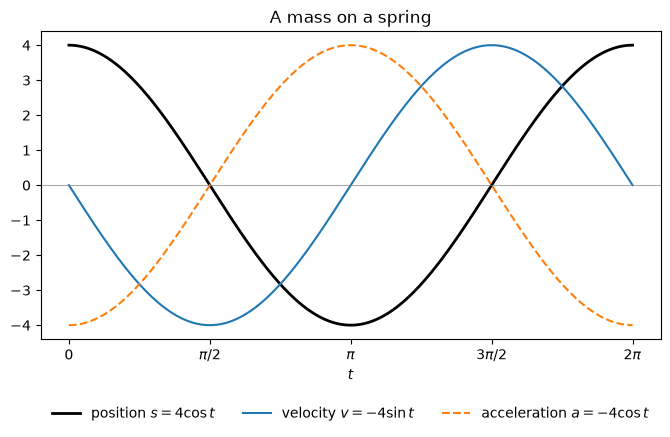

In [27]:
for f in [sp.sin(x), sp.cos(x), sp.tan(x), sp.csc(x), sp.sec(x), sp.cot(x)]:
    display(Math(rf"\frac{{d}}{{dx}}{sp.latex(f)} = {sp.latex(sp.diff(f, x))}"))


ts = np.linspace(0, 2 * np.pi, 300)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ts, 4 * np.cos(ts), "k", lw=2, label=r"position $s = 4\cos t$")
ax.plot(ts, -4 * np.sin(ts), lw=1.5, label=r"velocity $v = -4\sin t$")
ax.plot(ts, -4 * np.cos(ts), "--", lw=1.5, label=r"acceleration $a = -4\cos t$")
ax.axhline(0, color="gray", lw=0.5)
ax.set_xticks(np.arange(5) * np.pi / 2, ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
ax.set_xlabel("$t$")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
ax.set_title("A mass on a spring")
plt.show()

**Example 4.** Find the 27th derivative of $\cos x$.

*By hand.* The derivatives of $\cos x$ repeat in a cycle of four:
$$f(x) = \cos x,\quad f'(x) = -\sin x,\quad f''(x) = -\cos x,\quad f^{\prime\prime\prime}(x) = \sin x,\quad f^{(4)}(x) = \cos x, \;\ldots$$
So $f^{(n)}(x) = \cos x$ whenever $n$ is a multiple of $4$. Since $27 = 4\cdot 6 + 3$,
$$\frac{d^{27}}{dx^{27}}(\cos x) = \frac{d^{3}}{dx^{3}}(\cos x) = \sin x.$$

In [28]:
for k in range(9):
    display(Math(rf"f^{{({k})}}(x) = {sp.latex(sp.diff(sp.cos(x), x, k))}"))
display(Math(rf"f^{{(27)}}(x) = {sp.latex(sp.diff(sp.cos(x), x, 27))}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 6. Trigonometric limits

Limit 1 is useful well beyond proving derivative formulas. The trick is to make the argument of $\sin$ match the denominator.

**Example 5.** Find $\displaystyle\lim_{x\to0}\frac{\sin 7x}{4x}$.

*By hand.* Multiply and divide by $7$, and let $\theta = 7x$ (so $\theta\to0$ as $x\to0$):
$$\lim_{x\to0}\frac{\sin 7x}{4x} = \frac74\lim_{x\to0}\frac{\sin 7x}{7x} = \frac74\lim_{\theta\to0}\frac{\sin\theta}{\theta} = \frac74\cdot 1 = \frac74.$$

**Note:** $\sin 7x \neq 7\sin x$, so we cannot just cancel the $7$.

**Example 6.** Find $\displaystyle\lim_{x\to0} x\cot x$.

*By hand.* Write $\cot x = \dfrac{\cos x}{\sin x}$ and divide the numerator and denominator by $x$:
$$\lim_{x\to0} x\cot x = \lim_{x\to0}\frac{\cos x}{\dfrac{\sin x}{x}} = \frac{\lim_{x\to0}\cos x}{\lim_{x\to0}\dfrac{\sin x}{x}} = \frac{1}{1} = 1.$$

In [29]:
for expr, by_hand in [(sp.sin(7*x) / (4*x), sp.Rational(7, 4)), (x * sp.cot(x), 1)]:
    lim = sp.limit(expr, x, 0)
    display(Math(rf"\lim_{{x\to0}} {sp.latex(expr)} = {sp.latex(lim)}"))
    print("Agrees with by-hand answer:", lim == by_hand)
    fn = sp.lambdify(x, expr, "numpy")
    print("  numeric:", ", ".join(f"x={xv:g}: {fn(xv):.6f}" for xv in [0.1, 0.01, 0.001]))

<IPython.core.display.Math object>

Agrees with by-hand answer: True
  numeric: x=0.1: 1.610544, x=0.01: 1.748571, x=0.001: 1.749986


<IPython.core.display.Math object>

Agrees with by-hand answer: True
  numeric: x=0.1: 0.996664, x=0.01: 0.999967, x=0.001: 1.000000


## 7. A numerical sanity check

As in §3.2, we compare each by-hand derivative with a **central difference** $\dfrac{f(x+h) - f(x-h)}{2h}$ at many points. We use the interval $[0.2, 1.3]$, which avoids the vertical asymptotes of $\tan x$ and $\sec x$ at $x = \pi/2 \approx 1.57$.

In [30]:
def numeric_check(f, fprime, a=0.2, b=1.3, step=1e-5):
    fn, dfn = sp.lambdify(x, f, "numpy"), sp.lambdify(x, fprime, "numpy")
    xs = np.linspace(a, b, 200)
    approx = (fn(xs + step) - fn(xs - step)) / (2 * step)
    exact = dfn(xs)
    return np.max(np.abs(approx - exact)) / np.max(np.abs(exact))

tests = {
    r"\sin x": (sp.sin(x), sp.cos(x)),
    r"\cos x": (sp.cos(x), -sp.sin(x)),
    r"\tan x": (sp.tan(x), sp.sec(x)**2),
    r"\csc x": (sp.csc(x), -sp.csc(x) * sp.cot(x)),
    r"\sec x": (sp.sec(x), sp.sec(x) * sp.tan(x)),
    r"\cot x": (sp.cot(x), -sp.csc(x)**2),
    r"x^2 \sin x": (x**2 * sp.sin(x), x**2 * sp.cos(x) + 2*x * sp.sin(x)),
    r"\frac{\sec x}{1 + \tan x}": (sp.sec(x) / (1 + sp.tan(x)),
                                   sp.sec(x) * (sp.tan(x) - 1) / (1 + sp.tan(x))**2),
}
for name, (f, fp) in tests.items():
    rel = numeric_check(f, fp)
    display(Math(rf"{name}: \quad \text{{relative error}} \approx {rel:.1e}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 8. Practice problems

Try these by hand first, then run the cell below to check.

1. $f(x) = 3\sin x - 2\cos x$
2. $y = e^x\cos x$
3. $y = \dfrac{\sin x}{1 + \cos x}$ (*simplify your answer as far as you can*)
4. $f(\theta) = \theta\cos\theta\sin\theta$
5. Find the tangent line to $y = \sec x$ at $\left(\dfrac{\pi}{3}, 2\right)$.
6. Find $\displaystyle\lim_{x\to0}\frac{\sin 3x}{\sin 5x}$ and $\displaystyle\lim_{x\to0}\frac{\sin(x^2)}{x}$.
7. Find $\dfrac{d^{99}}{dx^{99}}(\sin x)$.

In [31]:
problems = [
    (3*sp.sin(x) - 2*sp.cos(x), x),
    (sp.exp(x) * sp.cos(x), x),
    (sp.sin(x) / (1 + sp.cos(x)), x),
    (theta * sp.cos(theta) * sp.sin(theta), theta),
]
for i, (f, var) in enumerate(problems, 1):
    df = sp.diff(f, var)
    df = sp.trigsimp(sp.simplify(df)) if i == 3 else df
    display(Math(rf"\text{{{i}.}}\quad \frac{{d}}{{d{sp.latex(var)}}}\left({sp.latex(f)}\right) = {sp.latex(df)}"))

# 5. tangent line
y = sp.sec(x)
m = sp.diff(y, x).subs(x, sp.pi / 3)
display(Math(rf"\text{{5.}}\quad y = 2 + {sp.latex(m)}\left(x - \frac{{\pi}}{{3}}\right)"))

# 6. limits
l1 = sp.limit(sp.sin(3*x) / sp.sin(5*x), x, 0)
l2 = sp.limit(sp.sin(x**2) / x, x, 0)
display(Math(rf"\text{{6.}}\quad {sp.latex(l1)}, \qquad {sp.latex(l2)}"))

# 7. 99 = 4·24 + 3
display(Math(rf"\text{{7.}}\quad {sp.latex(sp.diff(sp.sin(x), x, 99))}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Summary

| $f(x)$ | $f'(x)$ | | $f(x)$ | $f'(x)$ |
|---|---|---|---|---|
| $\sin x$ | $\cos x$ | | $\csc x$ | $-\csc x\cot x$ |
| $\cos x$ | $-\sin x$ | | $\sec x$ | $\sec x\tan x$ |
| $\tan x$ | $\sec^2 x$ | | $\cot x$ | $-\csc^2 x$ |

**Two key limits** (with $\theta$ in radians):
$$\lim_{\theta\to0}\frac{\sin\theta}{\theta} = 1 \qquad\qquad \lim_{\theta\to0}\frac{\cos\theta - 1}{\theta} = 0$$

**Key ideas.**
- The derivative formulas hold only when angles are measured in **radians**.
- $\sin$ and $\cos$ come from the limit definition and the addition formulas; the other four come from the Quotient Rule.
- The "co-" functions have minus signs in their derivatives.
- Derivatives of $\sin x$ and $\cos x$ repeat every four steps, so reduce $n$ modulo $4$ for high derivatives.
- For limits like $\dfrac{\sin kx}{x}$, rewrite them so the argument of $\sin$ matches the denominator.

**Previous:** [§3.2 The Product and Quotient Rules](product_and_quotient_rules.ipynb).